# 3. Deep Q-Networks (DQN) on CartPole

DQN replaces the Q-table with a neural network so Q-learning can handle continuous states. Two ideas from Mnih et al. (2015) make this stable:

- **Experience replay:** transitions go into a buffer, and the network trains on random mini-batches from it. This breaks the correlation between consecutive steps.
- **A target network:** a slowly updated copy of the Q-network computes the regression targets $r + \gamma \max_{a'} Q_{\text{target}}(s', a')$, so the targets don't shift with every gradient step.

This notebook studies three design choices on CartPole (Gymnasium `CartPole-v0`, maximum reward 200): how often the target network is updated, the mini-batch size, and the number of gradient steps per episode. Every setting is run with 3 random seeds.

In [1]:
import random
from collections import deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ENV_NAME = "CartPole-v0"
OBS_N, ACT_N = 4, 2
SEEDS = [1, 2, 3]

DEFAULTS = dict(
    episodes=300,
    hidden=512,
    lr=5e-4,
    gamma=0.99,
    buffer_size=10_000,
    batch_size=10,
    train_steps_per_episode=10,
    target_update_every=10,
    warmup_episodes=10,
    epsilon_start=1.0,
    epsilon_end=0.01,
    epsilon_decay_steps=10_000,
)

## Agent and training loop

In [2]:
def q_network(hidden):
    return nn.Sequential(
        nn.Linear(OBS_N, hidden), nn.ReLU(),
        nn.Linear(hidden, hidden), nn.ReLU(),
        nn.Linear(hidden, ACT_N),
    ).to(DEVICE)


def greedy_action(Q, obs):
    with torch.no_grad():
        return Q(torch.as_tensor(obs, dtype=torch.float32, device=DEVICE)).argmax().item()


def train_dqn(seed, **overrides):
    cfg = {**DEFAULTS, **overrides}
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    env, test_env = gym.make(ENV_NAME), gym.make(ENV_NAME)
    env.reset(seed=seed)
    test_env.reset(seed=seed + 10)
    env.action_space.seed(seed)

    Q, Q_target = q_network(cfg["hidden"]), q_network(cfg["hidden"])
    Q_target.load_state_dict(Q.state_dict())
    optimizer = torch.optim.Adam(Q.parameters(), lr=cfg["lr"])
    buffer = deque(maxlen=cfg["buffer_size"])

    epsilon = cfg["epsilon_start"]
    epsilon_step = (cfg["epsilon_start"] - cfg["epsilon_end"]) / cfg["epsilon_decay_steps"]
    gradient_steps = 0
    test_rewards, running_avg = [], []

    for episode in range(cfg["episodes"]):
        obs, _ = env.reset()
        done = False
        while not done:
            action = env.action_space.sample() if random.random() < epsilon else greedy_action(Q, obs)
            next_obs, reward, terminated, truncated, _ = env.step(action)
            buffer.append((obs, action, reward, next_obs, float(terminated)))
            obs, done = next_obs, terminated or truncated
            epsilon = max(cfg["epsilon_end"], epsilon - epsilon_step)

        if episode >= cfg["warmup_episodes"]:
            for _ in range(cfg["train_steps_per_episode"]):
                batch = random.sample(buffer, cfg["batch_size"])
                S, A, R, S2, D = (torch.as_tensor(np.array(x), dtype=torch.float32, device=DEVICE) for x in zip(*batch))
                q = Q(S).gather(1, A.long().view(-1, 1)).squeeze(1)
                with torch.no_grad():
                    target = R + cfg["gamma"] * Q_target(S2).max(dim=1).values * (1 - D)
                loss = F.mse_loss(q, target)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                gradient_steps += 1
                if gradient_steps % cfg["target_update_every"] == 0:
                    Q_target.load_state_dict(Q.state_dict())

        obs, _ = test_env.reset()
        done, total = False, 0.0
        while not done:
            obs, reward, terminated, truncated, _ = test_env.step(greedy_action(Q, obs))
            total += reward
            done = terminated or truncated
        test_rewards.append(total)
        running_avg.append(np.mean(test_rewards[-25:]))

    env.close()
    test_env.close()
    return np.array(running_avg)

After every episode the greedy policy plays one test episode, and the curves show the average test reward over the last 25 episodes. Only true terminations (the pole falling) stop the bootstrap; hitting the 200-step time limit does not, because the state there isn't actually terminal.

## Experiments

In [3]:
experiments = {
    "Target network update (every N gradient steps)": ("target_update_every", [1, 10, 30]),
    "Mini-batch size": ("batch_size", [1, 10, 30]),
    "Gradient steps per episode": ("train_steps_per_episode", [1, 5, 10, 50]),
}

cache = {}
def curves_for(param, value):
    key = tuple(sorted({**DEFAULTS, param: value}.items()))
    if key not in cache:
        cache[key] = np.stack([train_dqn(seed, **{param: value}) for seed in SEEDS])
    return cache[key]

results, rows = {}, []
for title, (param, values) in experiments.items():
    results[title] = {}
    for value in values:
        curves = curves_for(param, value)
        results[title][value] = curves
        mean_curve = curves.mean(axis=0)
        rows.append({
            "Experiment": title,
            "Value": value,
            "Mean reward over 300 episodes": mean_curve.mean().round(1),
            "Best 25-episode average": mean_curve.max().round(1),
            "Final 25-episode average (± std over seeds)": f"{curves[:, -1].mean():.1f} ± {curves[:, -1].std():.1f}",
        })

summary = pd.DataFrame(rows).set_index(["Experiment", "Value"])
summary

Mean reward over 300 episodes  \
Experiment                                     Value                                  
Target network update (every N gradient steps) 1                               92.6   
                                               10                             117.6   
                                               30                             127.8   
Mini-batch size                                1                               25.0   
                                               10                             117.6   
                                               30                             144.4   
Gradient steps per episode                     1                               26.2   
                                               5                               71.2   
                                               10                             117.6   
                                               50                             153.4   

                                                      Best 25-episode average  \
Experiment                                     Value                            
Target network update (every N gradient steps) 1                        161.4   
                                               10                       187.3   
                                               30                       188.5   
Mini-batch size                                1                         57.0   
                                               10                       187.3   
                                               30                       192.7   
Gradient steps per episode                     1                         50.2   
                                               5                        149.8   
                                               10                       187.3   
                                               50                       193.1   

                                                     Final 25-episode average (± std over seeds)  
Experiment                                     Value                                              
Target network update (every N gradient steps) 1                                    161.3 ± 37.8  
                                               10                                   184.0 ± 11.9  
                                               30                                    185.2 ± 4.3  
Mini-batch size                                1                                     55.0 ± 22.2  
                                               10                                   184.0 ± 11.9  
                                               30                                   152.0 ± 57.4  
Gradient steps per episode                     1                                     45.2 ± 11.5  
                                               5                                    141.7 ± 36.3  
                                               10                                   184.0 ± 11.9  
                                               50                                   130.9 ± 14.9

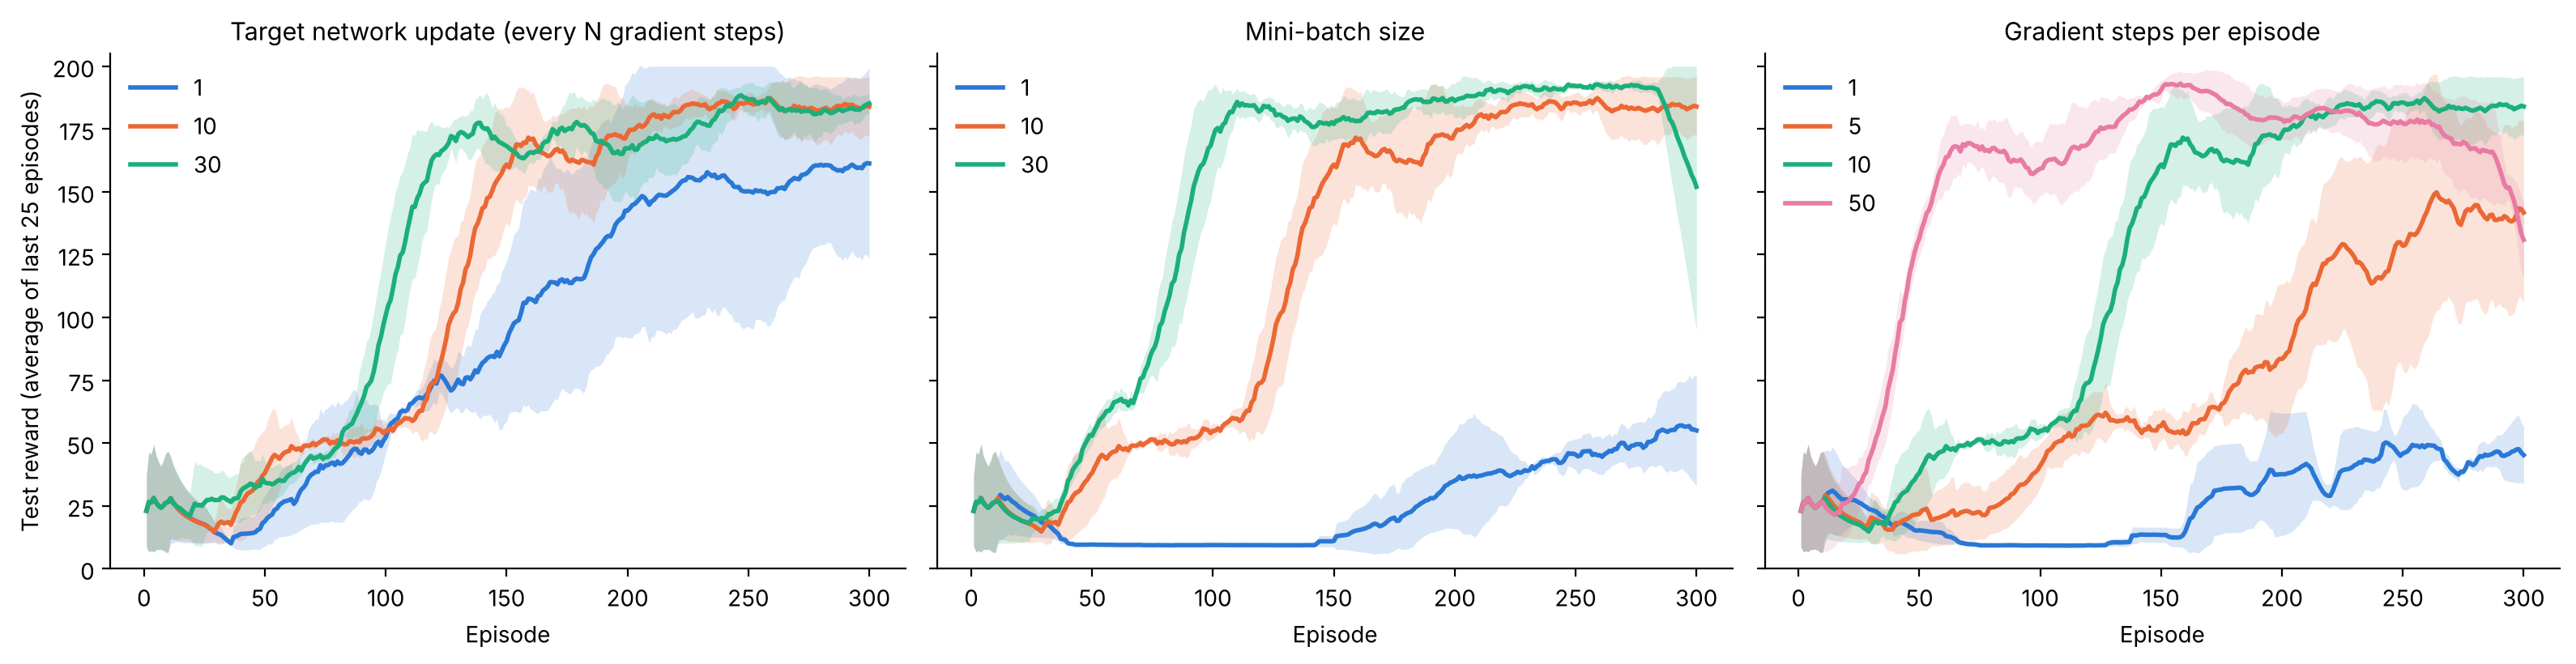

In [4]:
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (title, runs) in zip(axes, results.items()):
    for (value, curves), color in zip(runs.items(), colors):
        mean, std = curves.mean(axis=0), curves.std(axis=0)
        x = np.arange(1, len(mean) + 1)
        ax.plot(x, mean, color=color, lw=2, label=str(value))
        ax.fill_between(x, np.maximum(mean - std, 0), np.minimum(mean + std, 200), color=color, alpha=0.18, lw=0)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Episode")
    ax.set_ylim(0, 205)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Test reward (average of last 25 episodes)")
plt.tight_layout()
plt.savefig("figures/dqn_ablations.png", dpi=150)
plt.show()